# Phase 2 : Exploration des données RAVEN-I

Exploration du dataset `data/test-1k/` (**7 configurations × 1 000 échantillons = 7 000 problèmes**, `seed=42`, split **60 % train / 20 % val / 20 % test**) avec [`xml_parser.py`](../student_solutions/utils/xml_parser.py) et [`data_loader.py`](../student_solutions/utils/data_loader.py) :

- **Tâche 2.1 :** Visualiser des matrices 3×3 et leurs 8 candidats.
- **Tâche 2.2 :** Décoder `meta_matrix`, `meta_target`, `meta_answer_mods`, `.xml` et vérifier la cohérence sur les 7 000 problèmes.
- **Tâche 2.3 :** Statistiques du dataset (split, règles, configurations, attributs, cibles).
- **Validation DataLoader :** Tester `RAVENDataset` et `RAVENPanelDataset`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch.utils.data import DataLoader

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from student_solutions.utils.data_loader import RAVENDataset, RAVENPanelDataset, get_files
from student_solutions.utils.xml_parser import (
    ATTRIBUTES,
    COLORS,
    CONFIGURATIONS,
    RULES,
    SIZES,
    TYPES,
    decode_answer_mods,
    decode_meta_matrix,
    load_problem,
)

sns.set_theme(style="whitegrid", context="notebook")
DATA_DIR = PROJECT_ROOT / "data" / "test-1k"
print(f"Dataset : {DATA_DIR} ({len(CONFIGURATIONS)} configurations)")

Dataset : /home/samuel/Documentos/Masters/IAS/RAVEN-I /data/test-1k (7 configurations)


---
## Tâche 2.1 : Chargement et visualisation des matrices RAVEN-I

Chaque `.npz` contient `image` `(16, 160, 160)` : indices `0..7` = contexte (grille 3×3 sans la case en bas à droite), indices `8..15` = 8 candidats.

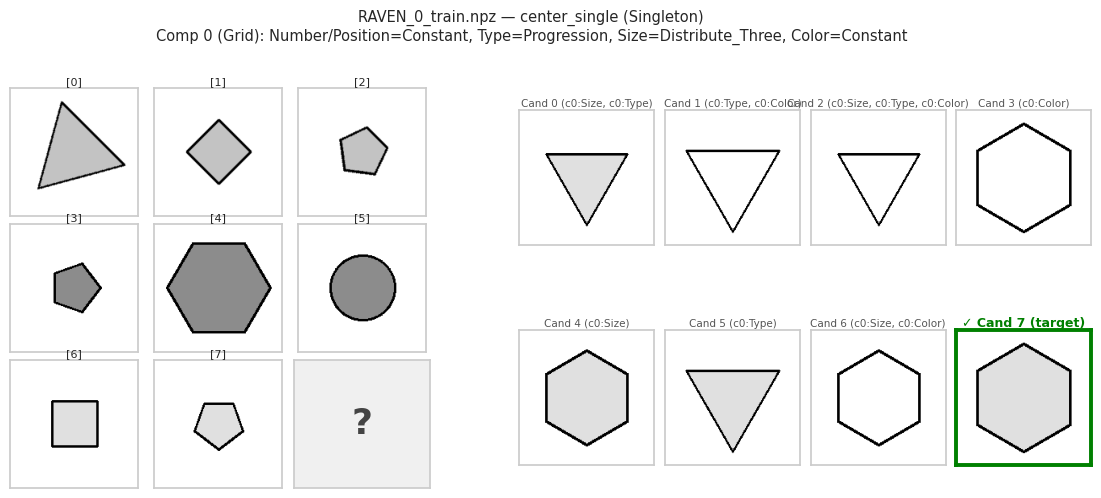

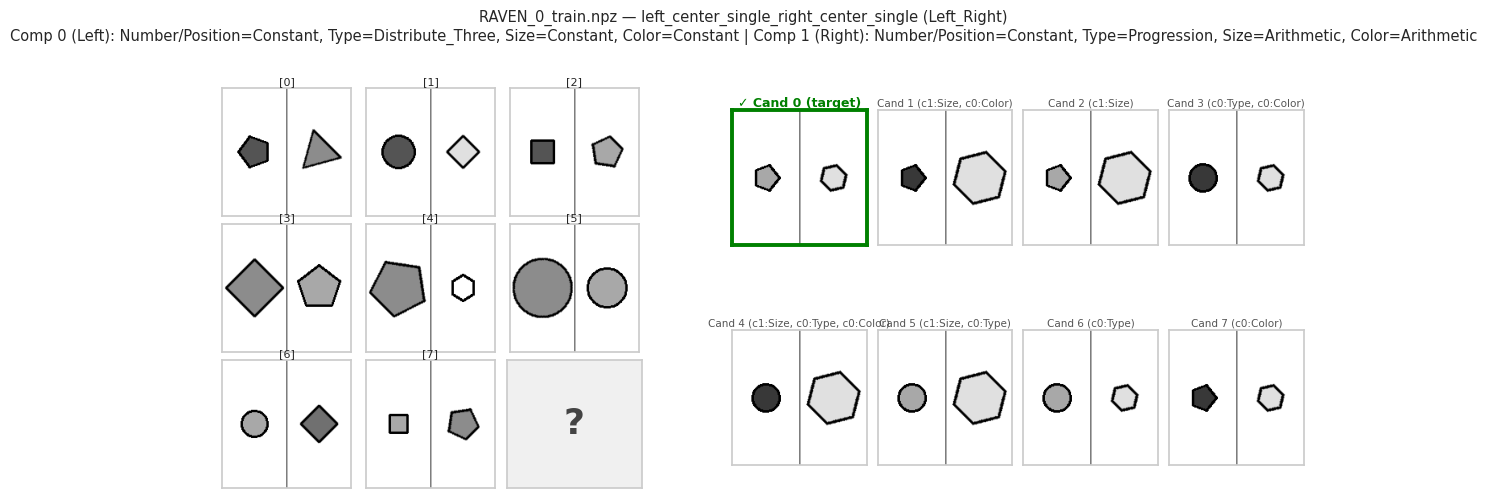

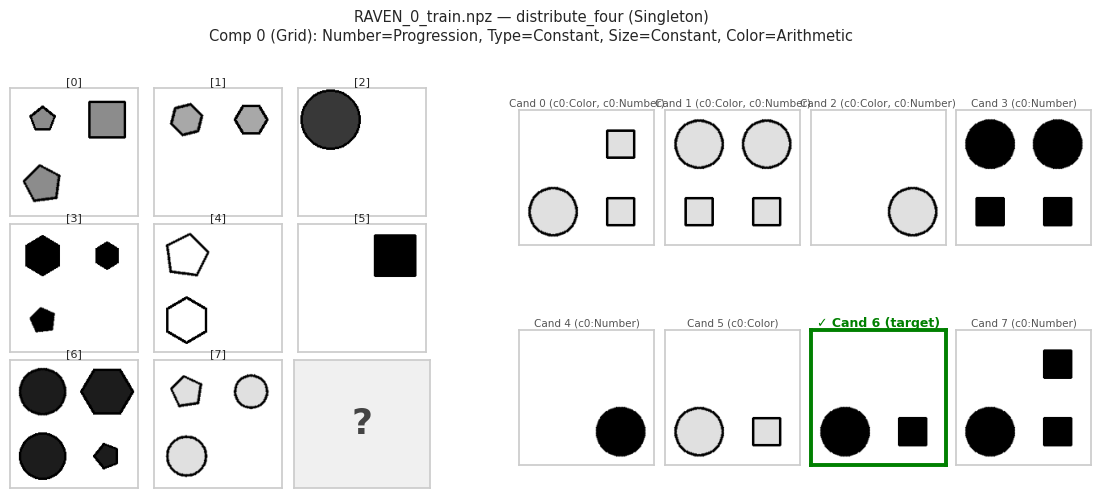

In [2]:
def plot_raven_problem(prob):
    imgs = prob["images"]
    fig = plt.figure(figsize=(14, 5.2))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.35], wspace=0.18)

    # Grille de contexte 3x3
    gs_ctx = gs[0].subgridspec(3, 3, wspace=0.06, hspace=0.06)
    for i in range(9):
        r, c = divmod(i, 3)
        ax = fig.add_subplot(gs_ctx[r, c])
        if i < 8:
            ax.imshow(imgs[i], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"[{i}]", fontsize=8, pad=2)
        else:
            ax.set_facecolor("#f0f0f0")
            ax.text(0.5, 0.5, "?", fontsize=26, fontweight="bold", ha="center", va="center", color="#444")
        ax.set_xticks([])
        ax.set_yticks([])

    # 8 candidats (2x4)
    gs_cand = gs[1].subgridspec(2, 4, wspace=0.08, hspace=0.22)
    for k in range(8):
        r, c = divmod(k, 4)
        ax = fig.add_subplot(gs_cand[r, c])
        ax.imshow(imgs[8 + k], cmap="gray", vmin=0, vmax=255)
        if k == prob["target"]:
            ax.set_title(f"✓ Cand {k} (target)", fontsize=9, fontweight="bold", color="green", pad=3)
            for spine in ax.spines.values():
                spine.set_edgecolor("green")
                spine.set_linewidth(2.8)
        else:
            mods = ", ".join(f"c{cid}:{attr}" for cid, attr in prob["candidate_mods"][k])
            ax.set_title(f"Cand {k} ({mods})", fontsize=7.5, color="#555", pad=3)
        ax.set_xticks([])
        ax.set_yticks([])

    rules_txt = " | ".join(
        f"Comp {i} ({prob['panels'][0][i]['name']}): "
        + ", ".join(f"{attr}={rule}" for rule, attr in comp_rules)
        for i, comp_rules in enumerate(prob["rules"])
    )
    fig.suptitle(
        f"{Path(prob['npz_path']).name} — {prob['config']} ({prob['struct']})\n{rules_txt}",
        fontsize=10.5,
        y=1.03,
    )
    plt.show()


for cfg in ["center_single", "left_center_single_right_center_single", "distribute_four"]:
    _, sample_path = get_files(DATA_DIR, cfg, "train", max_per_config=1)[0]
    plot_raven_problem(load_problem(sample_path, load_images=True))

---
## Tâche 2.2 : Analyse des représentations symboliques (`.npz` et `.xml`)

1. Décodage de `meta_matrix`, `meta_target`, `meta_answer_mods` et comparaison avec le `.xml`.
2. Affichage ligne par ligne des attributs de la matrice 3×3 (avec le candidat `target` en `(2, 2)`).
3. Vérification automatique de cohérence sur tous les **7 000 problèmes**.

In [3]:
_, ex_path = get_files(DATA_DIR, "center_single", "train", max_per_config=1)[0]
prob = load_problem(ex_path, load_images=False)

with np.load(ex_path, allow_pickle=True) as raw:
    print("Clés NPZ :", list(raw.keys()))
    print("structure :", raw["structure"].tolist())
    print("meta_structure :", raw["meta_structure"].tolist())

print("\nmeta_matrix (lignes actives) :")
print(prob["meta_matrix"][: prob["num_components"] * 4])
print("Règles XML :", prob["rules"])
print("Règles NPZ :", decode_meta_matrix(prob["meta_matrix"]))

mt = prob["meta_target"]
print(
    "meta_target :", mt.tolist(), "->",
    {"rules": [RULES[i] for i in range(4) if mt[i]], "attrs": [ATTRIBUTES[i] for i in range(5) if mt[4 + i]]},
)

print("\nmeta_answer_mods (NPZ) vs <Modified_attributes> (XML) :")
dec_mods = decode_answer_mods(prob["meta_answer_mods"], prob["num_components"])
for c in range(8):
    mark = " <-- TARGET" if c == prob["target"] else ""
    print(f"  Cand {c}: NPZ={dec_mods[c]} | XML={prob['candidate_mods'][c]}{mark}")

grid_idx = [0, 1, 2, 3, 4, 5, 6, 7, 8 + prob["target"]]
print("\nGrille 3x3 des attributs (target placé en bas à droite) :")
for r in range(3):
    cells_txt = []
    for c in range(3):
        cp = prob["panels"][grid_idx[r * 3 + c]][0]
        cells_txt.append(f"({TYPES[cp['type']][:3]}:{cp['type']}, Sz:{cp['size']}, Col:{cp['color']})")
    print(f"  Ligne {r + 1}: " + " | ".join(cells_txt))

Clés NPZ : ['image', 'target', 'predict', 'meta_matrix', 'meta_target', 'structure', 'meta_structure', 'meta_answer_mods']
structure : ['Scene', 'Singleton', 'Grid', 'Center_Single', '/', '/', '/', '/']
meta_structure : [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]

meta_matrix (lignes actives) :
[[1 0 0 0 1 1 0 0 0]
 [0 1 0 0 0 0 1 0 0]
 [0 0 0 1 0 0 0 1 0]
 [1 0 0 0 0 0 0 0 1]]
Règles XML : [[('Constant', 'Number/Position'), ('Progression', 'Type'), ('Distribute_Three', 'Size'), ('Constant', 'Color')]]
Règles NPZ : [[('Constant', 'Number/Position'), ('Progression', 'Type'), ('Distribute_Three', 'Size'), ('Constant', 'Color')]]
meta_target : [1, 1, 0, 1, 1, 1, 1, 1, 1] -> {'rules': ['Constant', 'Progression', 'Distribute_Three'], 'attrs': ['Number', 'Position', 'Type', 'Size', 'Color']}

meta_answer_mods (NPZ) vs <Modified_attributes> (XML) :
  Cand 0: NPZ=[(0, 'Type'), (0, 'Size')] | XML=[(0, 'Size'), (0, 'Type')]
  Cand 1: NPZ=[(0, 'Type'), (0, 'Color')] | XML=[(0,

In [4]:
split_rows, rule_rows, entity_rows, target_rows, uni_rows = [], [], [], [], []
checked = 0

for cfg in CONFIGURATIONS:
    for split in ("train", "val", "test"):
        files = get_files(DATA_DIR, cfg, split)
        split_rows.append({"config": cfg, "split": split, "count": len(files)})
        for _, path in files:
            p = load_problem(path, load_images=False)
            assert p["rules"] == decode_meta_matrix(p["meta_matrix"])
            assert len(p["candidate_mods"][p["target"]]) == 0

            dec_mods = decode_answer_mods(p["meta_answer_mods"], p["num_components"])
            for c in range(8):
                xml_set = set()
                for cid, attr in p["candidate_mods"][c]:
                    if attr == "Number/Position":
                        xml_set.update([(cid, "Number"), (cid, "Position")])
                    else:
                        xml_set.add((cid, attr))
                assert set(dec_mods[c]) == xml_set

            checked += 1
            target_rows.append({"config": cfg, "target": p["target"]})

            for comp_rules in p["rules"]:
                for rule_name, attr_name in comp_rules:
                    rule_rows.append({"config": cfg, "attr": attr_name, "rule": rule_name})

            for panel_idx in list(range(8)) + [8 + p["target"]]:
                for cp in p["panels"][panel_idx]:
                    assert cp["count"] == len(cp["entities"]) == int(cp["position_mask"].sum())
                    uni_rows.append({"num_slots": cp["num_slots"], "count": cp["count"], "uniformity": cp["uniformity"]})
                    for ent in cp["entities"]:
                        entity_rows.append({"type": ent["type"], "size": ent["size"], "color": ent["color"]})

print(f"Vérification terminée : {checked} / {checked} problèmes cohérents (.npz <-> .xml, 0 erreur).")

Vérification terminée : 7000 / 7000 problèmes cohérents (.npz <-> .xml, 0 erreur).


---
## Tâche 2.3 : Statistiques du dataset (`data/test-1k`)

split,train,val,test,total
config,,,,
center_single,600,200,200,1000
distribute_four,600,200,200,1000
distribute_nine,600,200,200,1000
in_center_single_out_center_single,600,200,200,1000
in_distribute_four_out_center_single,600,200,200,1000
left_center_single_right_center_single,600,200,200,1000
up_center_single_down_center_single,600,200,200,1000


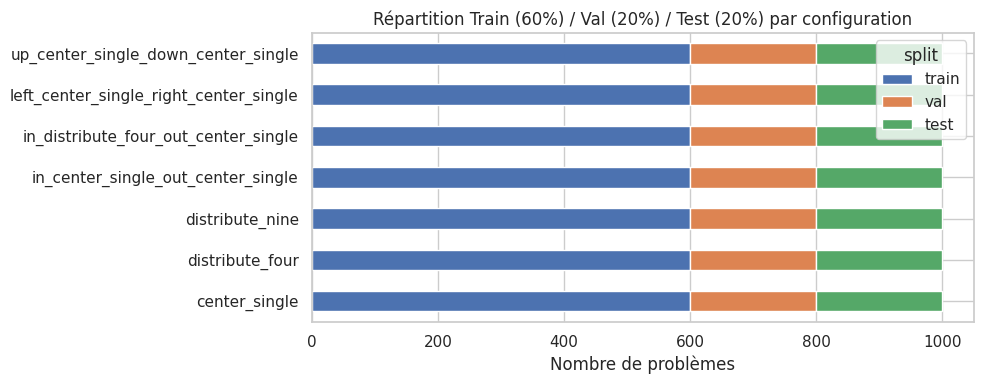

In [5]:
df_splits = pd.DataFrame(split_rows)
split_pivot = df_splits.pivot(index="config", columns="split", values="count")[["train", "val", "test"]]
split_pivot["total"] = split_pivot.sum(axis=1)
display(split_pivot)

fig, ax = plt.subplots(figsize=(10, 4))
split_pivot[["train", "val", "test"]].plot(kind="barh", stacked=True, ax=ax, color=["#4c72b0", "#dd8452", "#55a868"])
ax.set_title("Répartition Train (60%) / Val (20%) / Test (20%) par configuration")
ax.set_xlabel("Nombre de problèmes")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

rule,Constant,Progression,Arithmetic,Distribute_Three
attr,,,,
Number/Position,8476,0,0,0
Number,0,294,484,463
Position,0,298,500,485
Type,3728,3621,0,3651
Size,3093,2583,2261,3063
Color,4248,2216,2253,2283


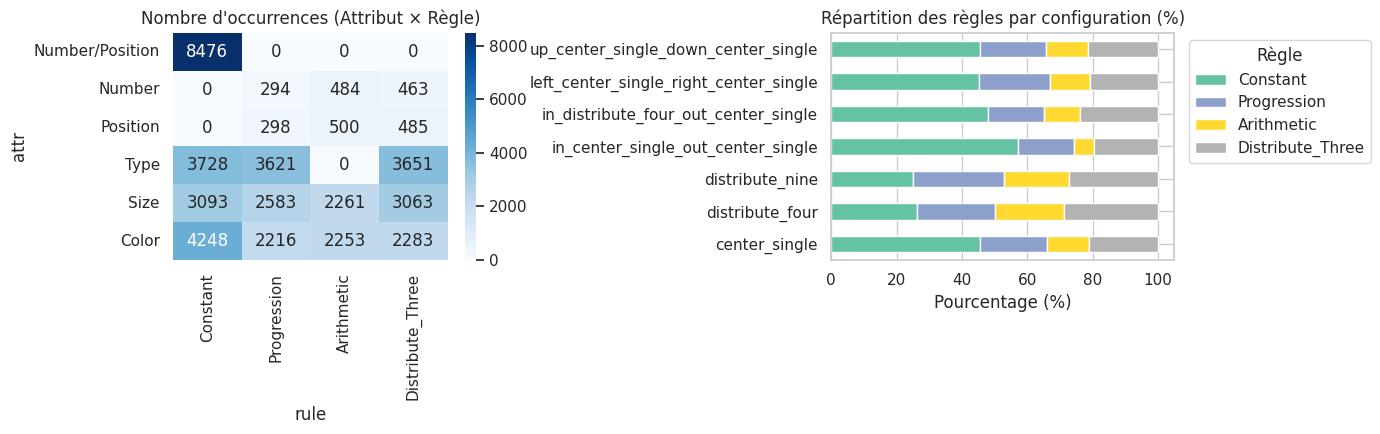

In [6]:
df_rules = pd.DataFrame(rule_rows)
rule_ct = pd.crosstab(df_rules["attr"], df_rules["rule"])
attr_order = [a for a in ["Number/Position", "Number", "Position", "Type", "Size", "Color"] if a in rule_ct.index]
rule_ct = rule_ct.reindex(index=attr_order, columns=RULES, fill_value=0)
display(rule_ct)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(rule_ct, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Nombre d'occurrences (Attribut × Règle)")

cfg_rule_ct = pd.crosstab(df_rules["config"], df_rules["rule"], normalize="index")[RULES] * 100
cfg_rule_ct.plot(kind="barh", stacked=True, ax=axes[1], colormap="Set2")
axes[1].set_title("Répartition des règles par configuration (%)")
axes[1].set_xlabel("Pourcentage (%)")
axes[1].set_ylabel("")
axes[1].legend(title="Règle", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

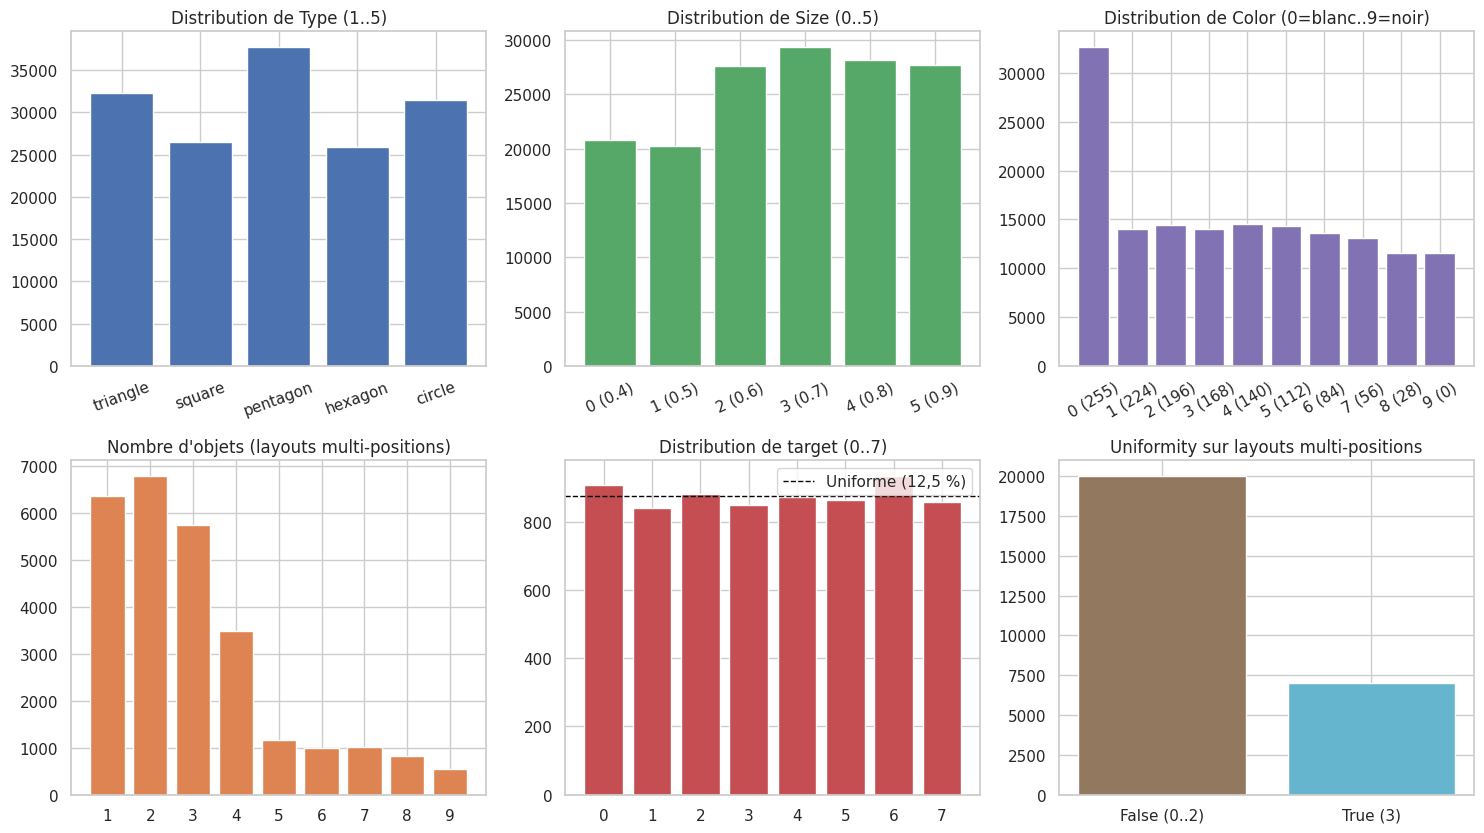

In [7]:
df_ent = pd.DataFrame(entity_rows)
df_uni = pd.DataFrame(uni_rows)
df_tgt = pd.DataFrame(target_rows)

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))

t_cnt = df_ent["type"].value_counts().sort_index()
axes[0, 0].bar([TYPES[i] for i in t_cnt.index], t_cnt.values, color="#4c72b0")
axes[0, 0].set_title("Distribution de Type (1..5)")
axes[0, 0].tick_params(axis="x", rotation=20)

s_cnt = df_ent["size"].value_counts().sort_index()
axes[0, 1].bar([f"{i} ({SIZES[i]})" for i in s_cnt.index], s_cnt.values, color="#55a868")
axes[0, 1].set_title("Distribution de Size (0..5)")
axes[0, 1].tick_params(axis="x", rotation=25)

c_cnt = df_ent["color"].value_counts().sort_index()
axes[0, 2].bar([f"{i} ({COLORS[i]})" for i in c_cnt.index], c_cnt.values, color="#8172b3")
axes[0, 2].set_title("Distribution de Color (0=blanc..9=noir)")
axes[0, 2].tick_params(axis="x", rotation=30)

df_multi = df_uni[df_uni["num_slots"] > 1]
n_cnt = df_multi["count"].value_counts().sort_index()
axes[1, 0].bar(n_cnt.index.astype(str), n_cnt.values, color="#dd8452")
axes[1, 0].set_title("Nombre d'objets (layouts multi-positions)")

tgt_cnt = df_tgt["target"].value_counts().sort_index()
axes[1, 1].bar(tgt_cnt.index.astype(str), tgt_cnt.values, color="#c44e52")
axes[1, 1].axhline(len(df_tgt) / 8, color="black", linestyle="--", linewidth=1, label="Uniforme (12,5 %)")
axes[1, 1].set_title("Distribution de target (0..7)")
axes[1, 1].legend()

u_cnt = df_multi["uniformity"].value_counts()
axes[1, 2].bar(["False (0..2)", "True (3)"], [u_cnt.get(False, 0), u_cnt.get(True, 0)], color=["#937860", "#64b5cd"])
axes[1, 2].set_title("Uniformity sur layouts multi-positions")

plt.tight_layout()
plt.show()

---
## Validation des DataLoaders PyTorch

In [8]:
prob_ds = RAVENDataset(DATA_DIR, configs=None, split="train", image_size=80, max_per_config=10)
prob_batch = next(iter(DataLoader(prob_ds, batch_size=8, shuffle=True)))
print("RAVENDataset (batch=8, image_size=80) :")
for k, v in prob_batch.items():
    if isinstance(v, torch.Tensor):
        print(f"  {k:15s}: shape={tuple(v.shape)}, dtype={v.dtype}, min={v.min().item():.2f}, max={v.max().item():.2f}")

panel_ds = RAVENPanelDataset(DATA_DIR, configs="center_single", split="train", image_size=80, max_per_config=20)
panel_batch = next(iter(DataLoader(panel_ds, batch_size=32, shuffle=True)))
print(f"\nRAVENPanelDataset center_single (total={len(panel_ds)} panneaux, batch=32) :")
for k, v in panel_batch.items():
    if isinstance(v, torch.Tensor):
        print(f"  {k:15s}: shape={tuple(v.shape)}, dtype={v.dtype}, min={v.min().item():.2f}, max={v.max().item():.2f}")

RAVENDataset (batch=8, image_size=80) :
  images         : shape=(8, 16, 80, 80), dtype=torch.float32, min=0.00, max=1.00
  target         : shape=(8,), dtype=torch.int64, min=0.00, max=7.00
  type           : shape=(8, 16, 2), dtype=torch.int64, min=-1.00, max=4.00
  size           : shape=(8, 16, 2), dtype=torch.int64, min=-1.00, max=5.00
  color          : shape=(8, 16, 2), dtype=torch.int64, min=-1.00, max=9.00
  number         : shape=(8, 16, 2), dtype=torch.int64, min=-1.00, max=4.00
  position_mask  : shape=(8, 16, 2, 9), dtype=torch.float32, min=0.00, max=1.00
  rules          : shape=(8, 2, 4), dtype=torch.int64, min=-1.00, max=3.00
  num_components : shape=(8,), dtype=torch.int64, min=1.00, max=2.00
  config_idx     : shape=(8,), dtype=torch.int64, min=1.00, max=6.00

RAVENPanelDataset center_single (total=320 panneaux, batch=32) :
  image          : shape=(32, 1, 80, 80), dtype=torch.float32, min=0.00, max=1.00
  type           : shape=(32, 2), dtype=torch.int64, min=-1.00, 

---
## Points clés pour la suite

1. **Règles par ligne uniquement** (jamais par colonne).
2. **`Number` est 0-indexé dans le XML** (`count = Number + 1`).
3. **`Type` vaut `1..5` dans le XML** (décalé en `0..4` dans le `DataLoader` pour `CrossEntropyLoss`), et **`Arithmetic` n'existe pas sur `Type`**.
4. **`Color=0` (blanc) est surreprésenté** car `Out_Center_Single` fixe toujours le contour externe en blanc (`color_max=0`).
5. **`Uniformity=False` sur multi-objets** : quand une règle est `Constant`, plusieurs entités d'une même case peuvent avoir des attributs différents.